In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use("root")

Loading All Events...
Loading Direct Signal...
Loading Indirect Signal...

Cutflow Summary: All Events
Cut Step                     | Raw Events   | Weighted Events 
All Events (No Cuts)         | 91215        | 91215.00        
SciFi DS Timing              | 85361        | 85361.00        
DS Dimuon                    | 47725        | 47725.00        
Two DS Tracks                | 26644        | 26644.00        
Veto Cut (No Veto Hits)      | 1723         | 1723.00         

Cutflow Summary: Direct Signal
Cut Step                     | Raw Events   | Weighted Events 
All Events (No Cuts)         | 347          | 347.00          
SciFi DS Timing              | 346          | 346.00          
DS Dimuon                    | 300          | 300.00          
Two DS Tracks                | 229          | 229.00          
Veto Cut (No Veto Hits)      | 16           | 16.00           

Cutflow Summary: Indirect Signal
Cut Step                     | Raw Events   | Weighted Events 
All Events (

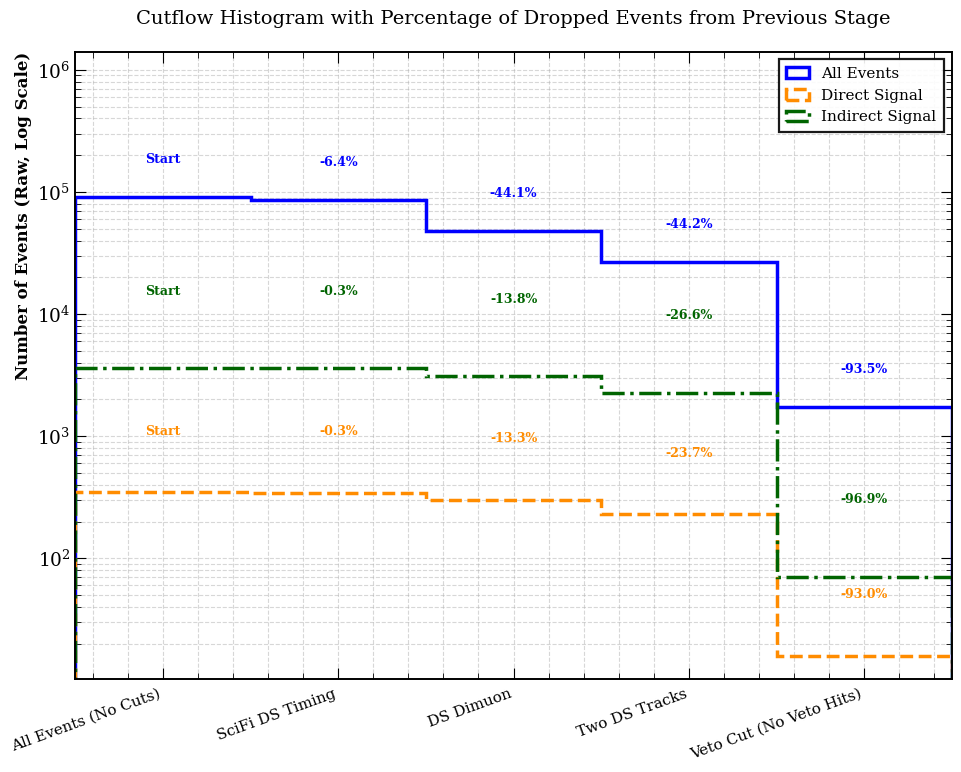

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# File paths on EOS
files = {
    'All Events': '/eos/user/i/idioniso/snd-numu-charm/signal/2022_down_nu14_all_cut_table.csv',
    'Direct Signal': '/eos/user/i/idioniso/snd-numu-charm/signal/2022_down_nu14_direct_signal_cut_table.csv',
    'Indirect Signal': '/eos/user/i/idioniso/snd-numu-charm/signal/2022_down_nu14_indirect_signal_cut_table.csv',
}

# Define the sequence of cuts in your requested order:
cut_steps = [
    ('All Events (No Cuts)', None),
    ('SciFi DS Timing', 'pass_scifi_ds_timing'),
    ('DS Dimuon', 'pass_ds_dimuon'),
    ('Two DS Tracks', 'pass_two_ds_tracks'),
    ('Veto Cut (No Veto Hits)', 'pass_no_veto_hits'),
]

cut_labels = [s[0] for s in cut_steps]
results_raw = {}
results_weighted = {}

# Process each file
for name, path in files.items():
  print(f'Loading {name}...')
  df = pd.read_csv(path)

  raw_counts = []
  weighted_counts = []
  current_df = df

  for label, col in cut_steps:
    if col is not None:
      current_df = current_df[current_df[col] == 1]
    raw_counts.append(len(current_df))
    weighted_counts.append(current_df['mc_weight'].sum())

  results_raw[name] = raw_counts
  results_weighted[name] = weighted_counts

# Print summary tables to terminal
for name in files.keys():
  print('\n' + '=' * 65)
  print(f'Cutflow Summary: {name}')
  print('=' * 65)
  print(f'{"Cut Step":<28} | {"Raw Events":<12} | {"Weighted Events":<16}')
  print('=' * 65)
  for label, raw, weighted in zip(
      cut_labels, results_raw[name], results_weighted[name]
  ):
    print(f'{label:<28} | {raw:<12} | {weighted:<16.2f}')
print('=' * 65)

# --- Plotting as an unfilled histogram with drop-percentage annotations ---
fig, ax = plt.subplots(figsize=(10, 8))

bins = np.arange(len(cut_labels) + 1) - 0.5
x_centers = np.arange(len(cut_labels))

styles = {
    'All Events': {
        'color': 'b',
        'linestyle': '-',
        'text_y_offset': 1.8,
    },
    'Direct Signal': {
        'color': 'darkorange',
        'linestyle': '--',
        'text_y_offset': 2.8,
    },
    'Indirect Signal': {
        'color': 'darkgreen',
        'linestyle': '-.',
        'text_y_offset': 3.8,
    },
}

for name, counts in results_raw.items():
  # Plot histogram step line
  ax.hist(
      x_centers,
      bins=bins,
      weights=counts,
      histtype='step',
      linewidth=2.5,
      label=name,
      color=styles[name]['color'],
      linestyle=styles[name]['linestyle'],
  )

  # Calculate and annotate drop percentages relative to the previous stage
  for i, count in enumerate(counts):
    if i == 0:
      label_text = 'All events'
    else:
      prev_count = counts[i - 1]
      if prev_count > 0:
        dropped_pct = ((prev_count - count) / prev_count) * 100
        label_text = f'-{dropped_pct:.1f}%'
      else:
        label_text = '0.0%'

    # Position text slightly above the step top, staggered per dataset to avoid overlap
    y_pos = count * styles[name]['text_y_offset']
    ax.text(
        x_centers[i],
        y_pos,
        label_text,
        ha='center',
        va='bottom',
        fontsize=9,
        color=styles[name]['color'],
        fontweight='bold',
    )

ax.set_ylabel('Number of Events', fontsize=12)
ax.set_yscale('log')
ax.set_title(
    'Percentage of dropped events from previous Stage',
    fontsize=14,
    pad=20,
)

ax.set_xticks(x_centers)
ax.set_xticklabels(cut_labels, rotation=20, ha='right', fontsize=11)
ax.set_xlim(bins[0], bins[-1])

# Expand y-axis limits slightly to ensure the text annotations don't get cut off at the top
ymin, ymax = ax.get_ylim()
ax.set_ylim(ymin, ymax * 10)

ax.legend(fontsize=11, frameon=True, facecolor='white', framealpha=0.9)
ax.grid(True, which='both', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [2]:
df = pd.read_csv("/eos/user/i/idioniso/snd-numu-charm/signal/2022_down_nu14_indirect_signal_cut_table.csv")
df.columns

Index(['partition', 'event_number', 'entry', 'signal_type', 'mc_weight',
       'raw_weight', 'nu_e', 'charm_pdg', 'pass_lhc_ip1', 'pass_stable_beams',
       'pass_event_deltat', 'pass_scifi_ds_timing', 'pass_no_veto_hits',
       'pass_ds_dimuon', 'pass_two_ds_tracks', 'pass_all_cuts', 'n_veto_hits',
       'n_ds_tracks'],
      dtype='object')

In [4]:
pass_cols = [
    'pass_lhc_ip1', 
    'pass_stable_beams', 
    'pass_event_deltat', 
    'pass_scifi_ds_timing', 
    'pass_no_veto_hits', 
    'pass_ds_dimuon'
]

# pass_cols = [
#     'pass_lhc_ip1', 
#     'pass_stable_beams', 
#     'pass_event_deltat', 
#     'pass_scifi_ds_timing', 
#     'pass_ds_dimuon'
# ]

# Filter the DataFrame
df[df[pass_cols].all(axis=1) & (df['n_ds_tracks'] == 2)].head(25)

,partition,event_number,entry,signal_type,mc_weight,raw_weight,nu_e,charm_pdg,pass_lhc_ip1,pass_stable_beams,pass_event_deltat,pass_scifi_ds_timing,pass_no_veto_hits,pass_ds_dimuon,pass_two_ds_tracks,pass_all_cuts,n_veto_hits,n_ds_tracks
40,10,202,0,direct,1.0,0.0,723.476313,431,1,1,1,1,1,1,1,1,0,2
42,11,47541,0,direct,1.0,0.0,259.855564,-431,1,1,1,1,1,1,1,1,0,2
149,41,29813,0,direct,1.0,0.0,886.074969,411,1,1,1,1,1,1,1,1,0,2
292,80,3476,2,direct,1.0,0.0,443.754338,421,1,1,1,1,1,1,1,1,0,2
307,84,22207,2,direct,1.0,0.0,136.902879,4122,1,1,1,1,1,1,1,1,0,2
312,88,71351,1,direct,1.0,0.0,611.186337,-421,1,1,1,1,1,1,1,1,0,2
315,88,11408,4,direct,1.0,0.0,537.527020,-421,1,1,1,1,1,1,1,1,0,2
365,103,7957,0,direct,1.0,0.0,97.022420,431,1,1,1,1,1,1,1,1,0,2
411,116,30761,0,direct,1.0,0.0,223.915088,-421,1,1,1,1,1,1,1,1,0,2
472,134,34366,2,direct,1.0,0.0,392.764019,421,1,1,1,1,1,1,1,1,0,2
